# Bonus B1: How to make a LangGraph workflow survive a restart

## Goal

We keep a refund review waiting on disk, restart Python, then approve that same saved request. The moment is a counter: the review node is entered once before the pause and again after the restart, so any code placed before `interrupt()` runs twice. Saving the workflow does not make a payment safe to repeat.

## What you will learn

- How to build a `StateGraph` from state, nodes and edges, without a model.
- How to merge updates from parallel checks with a reducer, and what the error looks like without one.
- How to read a checkpoint's business values, scheduled nodes and waiting interrupt.
- How to resume the same SQLite-backed thread in a new Python process.
- How to fork an earlier checkpoint without changing the original saved result.
- When a durable workflow is worth it, compared with the agents of labs 07 and 08.

No API, account or key is needed. All refunds here are simulated records: no money is sent and no customer data is changed.

## Setup

Use the repository environment (`uv sync --python 3.13` from the repository folder), then select its Python kernel. The setup locates the repository by `models.env`, but does not load model settings or credentials because this lab calls no model. It works from this folder or `solved/`.

Runtime files go in this lab's gitignored `outputs/`. Run the notebook in order, stopping for the explicit kernel restart in Part D. **Do not use Run All across that boundary.**

In [1]:
from pathlib import Path
import json
import operator
import os
import sys
from importlib.metadata import version
from typing import Annotated, Literal, TypedDict

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'models.env').exists())
LAB = ROOT / 'bonus' / 'B1_LangGraph_Durable_Workflows'
OUTPUTS = LAB / 'outputs'
OUTPUTS.mkdir(exist_ok=True)
ATTEMPTS = OUTPUTS / 'review_attempts.json'
ATTEMPTS.write_text('{}')  # reset this lab's demonstration counter before starting

from langgraph.graph import END, START, StateGraph
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import Command, interrupt

print('langgraph:', version('langgraph'))
print('SQLite checkpointer:', version('langgraph-checkpoint-sqlite'))
print('model calls: 0 | API cost: $0.00')

langgraph: 1.2.19
SQLite checkpointer: 3.1.3
model calls: 0 | API cost: $0.00


## Part A: Represent a refund as state and node updates

A support request must keep its amount as it moves between steps. Start with one record so we can see exactly what a graph changes. **State** is the current record. A **node** is a function that receives that record and returns the fields it changes. An **edge** chooses which node runs next.

This small example rounds one amount. `case_id` identifies our simulated request; it is not an invoice number in Chinook.

In [2]:
small_case = {'case_id': 'case-small', 'amount_usd': 45.126}
print(small_case)

{'case_id': 'case-small', 'amount_usd': 45.126}


The dictionary has two fields, one string and one number. `TypedDict` below describes their names and types for readers and type checkers; it does not validate values at runtime. The node returns only `amount_usd`, so the graph should retain `case_id`.

In [3]:
class AmountState(TypedDict):
    case_id: str
    amount_usd: float


def round_amount(state: AmountState) -> dict:
    return {'amount_usd': round(state['amount_usd'], 2)}


print('node update:', round_amount(small_case))
print('input unchanged:', small_case)

node update: {'amount_usd': 45.13}
input unchanged: {'case_id': 'case-small', 'amount_usd': 45.126}


`45.13` is an update, rather than the whole record. The original input is still `45.126` because the node returned a new dictionary. Now use the library directly: register the node, link `START` to it and it to `END`, then compile. Compiling checks the wiring and creates the runnable graph.

In [4]:
small_builder = StateGraph(AmountState)
small_builder.add_node('round_amount', round_amount)
small_builder.add_edge(START, 'round_amount')
small_builder.add_edge('round_amount', END)
small_graph = small_builder.compile()
print('object:', type(small_graph).__name__)
print('nodes:', list(small_graph.get_graph().nodes))
small_result = small_graph.invoke(small_case)
print('result:', small_result)
assert small_result == {'case_id': 'case-small', 'amount_usd': 45.13}

object: CompiledStateGraph
nodes: ['__start__', 'round_amount', '__end__']
result: {'case_id': 'case-small', 'amount_usd': 45.13}


`CompiledStateGraph` runs our function between the start and end markers. The result retains the ID and replaces the amount. No model chose a step; this is a workflow whose route we wrote.

**Checkpoint A:** explain why the input still holds `45.126` while the graph result holds `45.13`. The assertion checks that applying the partial update preserves the other field. Next we need two independent checks to contribute to one record.

## Part B: Merge updates from parallel checks

An amount check and a return check can run independently. Both may add a review signal. We need a merge rule so one check cannot overwrite the other's result.

A **reducer** combines an existing field value with an update. For lists, `operator.add` joins the lists. Try the mechanism on two labels before attaching it to graph state.

In [5]:
left = ['opened_item']
right = ['high_amount']
print('list merge:', operator.add(left, right))
print('original lists:', left, right)

list merge: ['opened_item', 'high_amount']
original lists: ['opened_item'] ['high_amount']


The merged list keeps both strings; the two input lists are unchanged. Addition would be wrong for a corrected amount: changing $1,250 to $80 should replace the amount, not add $80.

First leave the reducer out. Both nodes below write `signals` in the same **super-step**, a graph step in which independent nodes can run in parallel. The default field rule accepts a single replacement, so two replacements conflict. We catch the expected error to keep the notebook runnable.

In [6]:
from langgraph.errors import InvalidUpdateError

class UnmergedState(TypedDict):
    signals: list[str]


def check_opened(state):
    return {'signals': ['opened_item']}


def check_amount(state):
    return {'signals': ['high_amount']}


broken_builder = StateGraph(UnmergedState)
broken_builder.add_node('check_opened', check_opened)
broken_builder.add_node('check_amount', check_amount)
broken_builder.add_edge(START, 'check_opened')
broken_builder.add_edge(START, 'check_amount')
broken_builder.add_edge(['check_opened', 'check_amount'], END)
try:
    broken_builder.compile().invoke({'signals': []})
except InvalidUpdateError as exc:
    print(type(exc).__name__ + ':', str(exc).splitlines()[0])

InvalidUpdateError: At key 'signals': Can receive only one value per step. Use an Annotated key to handle multiple values.


`Can receive only one value per step` tells us which assumption failed: a plain `signals` list has no rule for concurrent updates. This error is about merging, not about whether a refund is allowed.

`Annotated[list[str], operator.add]` attaches the merge function to the field's type. Rebuild the same two-node graph with only that state rule changed.

In [7]:
class MergedState(TypedDict):
    signals: Annotated[list[str], operator.add]


merged_builder = StateGraph(MergedState)
merged_builder.add_node('check_opened', check_opened)
merged_builder.add_node('check_amount', check_amount)
merged_builder.add_edge(START, 'check_opened')
merged_builder.add_edge(START, 'check_amount')
merged_builder.add_edge(['check_opened', 'check_amount'], END)
merged_result = merged_builder.compile().invoke({'signals': []})
print(merged_result)
assert set(merged_result['signals']) == {'opened_item', 'high_amount'}

{'signals': ['high_amount', 'opened_item']}


Both signals survive. The check uses a set because what matters is which signals are present, not which branch finished first.

**Checkpoint B:** without the reducer, `InvalidUpdateError`; with it, both labels. The graph now has the merge rule our refund workflow needs.

## Part C: Join refund checks before choosing a route

Build the full workflow around the same state/update mechanism. A **fan-out** schedules both checks; a **fan-in** waits for both before choosing auto approval or human review.

We use deliberately simplified review rules for simulated physical-return requests: review an amount of at least $500, an opened item, or a request beyond 30 days. These are teaching rules, not a complete implementation of Chinook's policies. For example, its [returns policy](../../../data/corpus/policy_returns.md) allows defective opened media in a separate 14-day window. Review means a person must decide; it does not mean the refund is invalid.

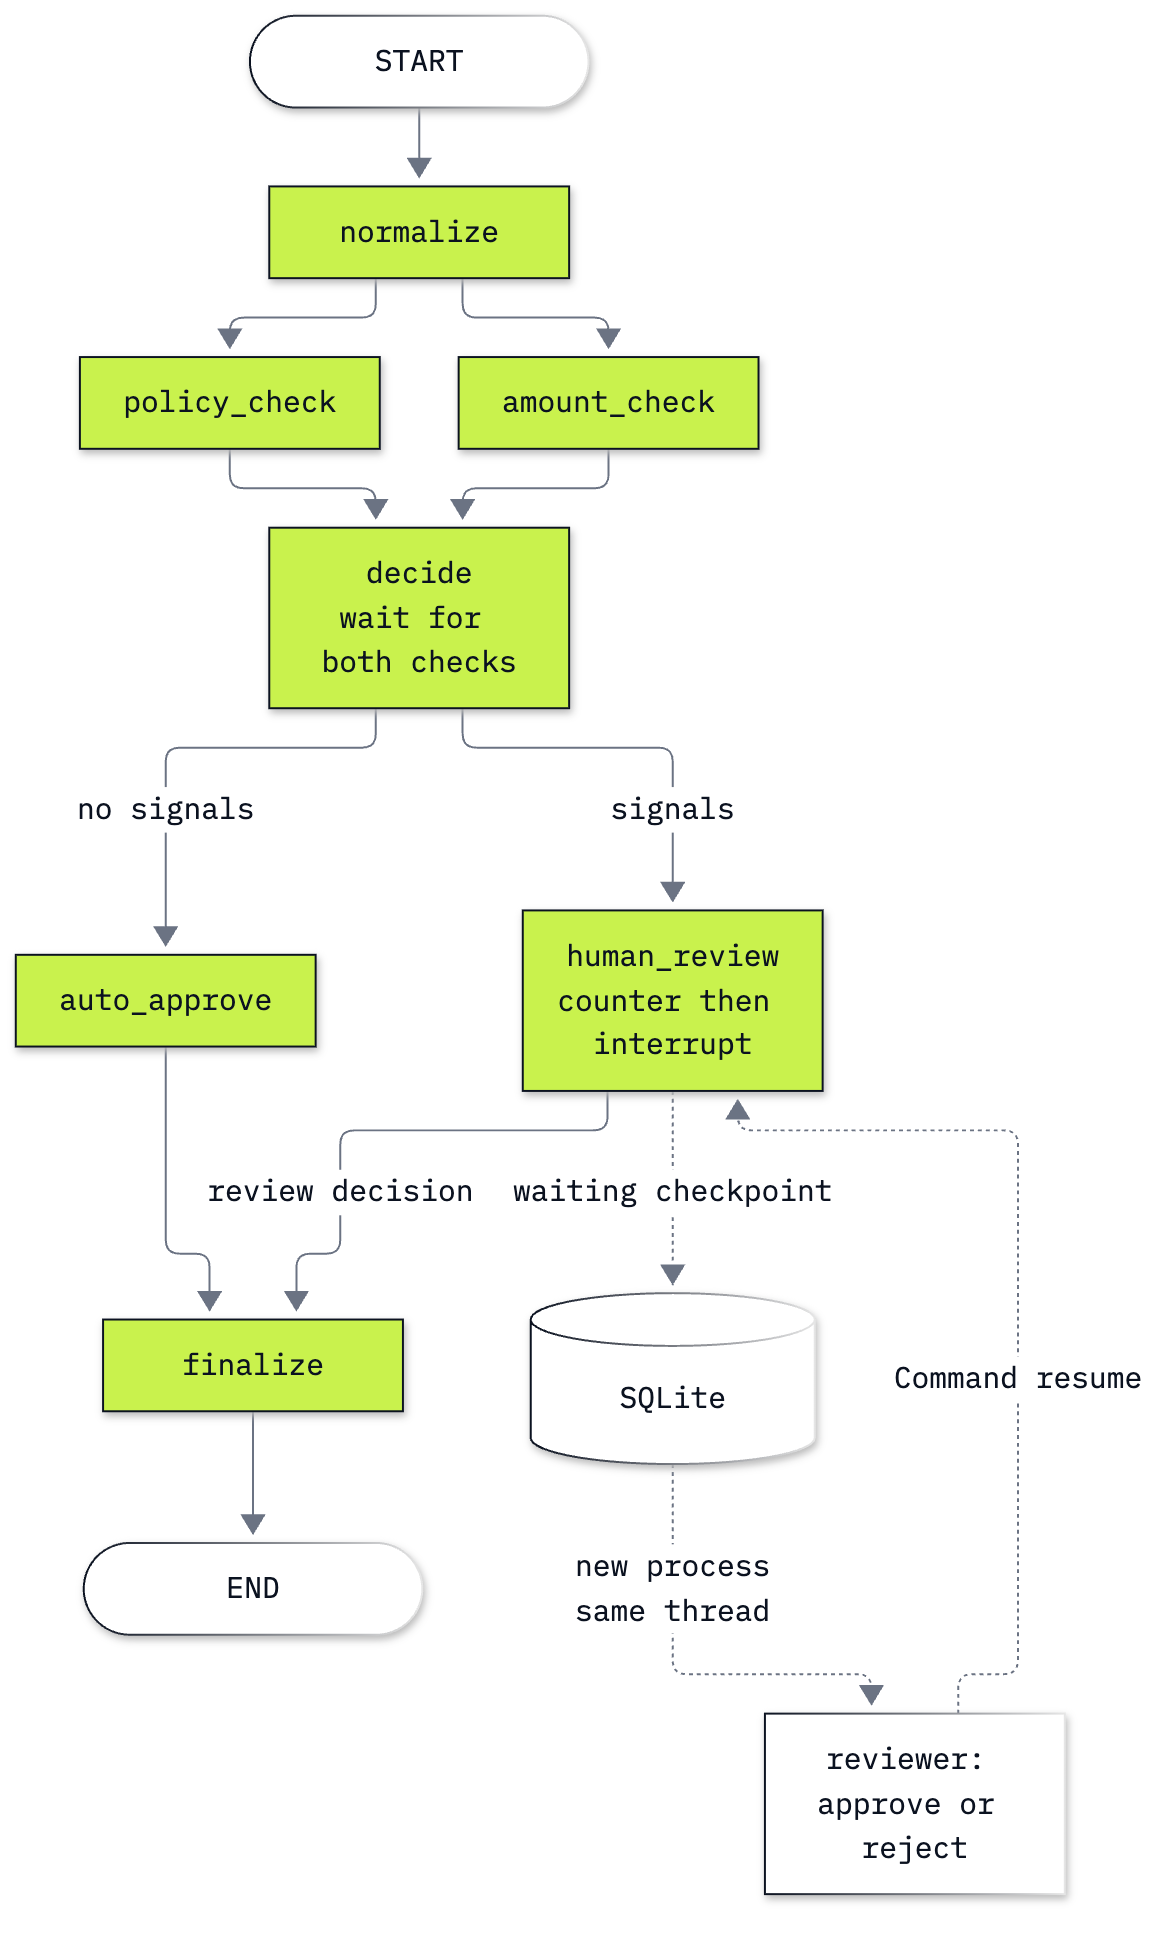

In [8]:
from IPython.display import Image, display

display(Image(filename=str(LAB / 'resources' / 'labB1_refund_workflow.png'), width=760))

Read arrows as scheduled work. Lime nodes are code we write. The two checks share a super-step and their list updates merge before `decide`. The human-review branch pauses; its answer later reaches `finalize`. SQLite stores checkpoints alongside execution, including the work waiting to run next.

Here is the complete input before any node uses it:

In [9]:
auto_case = {
    'case_id': 'case-auto', 'amount_usd': 45.126,
    'days_since_purchase': 10, 'item_opened': False,
    'signals': [], 'audit_log': [], 'needs_review': False, 'decision': '',
}
print(json.dumps(auto_case, indent=2))

{
  "case_id": "case-auto",
  "amount_usd": 45.126,
  "days_since_purchase": 10,
  "item_opened": false,
  "signals": [],
  "audit_log": [],
  "needs_review": false,
  "decision": ""
}


The first four fields describe the request. `signals` collects reasons to review; `audit_log` records completed node updates. `needs_review` controls routing, and `decision` is empty until a branch decides. Only the two lists use append reducers. The other fields are replaced when a node changes them.

In [10]:
class RefundState(TypedDict):
    case_id: str
    amount_usd: float
    days_since_purchase: int
    item_opened: bool
    signals: Annotated[list[str], operator.add]
    audit_log: Annotated[list[str], operator.add]
    needs_review: bool
    decision: str

Normalization changes only the amount and adds an audit entry. The policy check reads the age and opened flag and returns any signals. Run them as ordinary functions on the visible input before letting the graph schedule them.

In [11]:
def normalize(state: RefundState) -> dict:
    return {'amount_usd': round(state['amount_usd'], 2),
            'audit_log': ['normalized']}

def policy_check(state: RefundState) -> dict:
    signals = []
    if state['days_since_purchase'] > 30:
        signals.append('outside_30_day_window')
    if state['item_opened']:
        signals.append('opened_item')
    return {'signals': signals, 'audit_log': ['policy_check']}

print('normalization:', normalize(auto_case))
print('policy update:', policy_check(auto_case))

normalization: {'amount_usd': 45.13, 'audit_log': ['normalized']}
policy update: {'signals': [], 'audit_log': ['policy_check']}


An empty `signals` update means the policy check found no review reason in this input. The amount check adds the other independent review reason. `decide` runs after both updates have merged; `bool(...)` is true for a nonempty list. The routing function returns a node name.

In [12]:
def amount_check(state: RefundState) -> dict:
    signals = ['high_amount'] if state['amount_usd'] >= 500 else []
    return {'signals': signals, 'audit_log': ['amount_check']}

def decide(state: RefundState) -> dict:
    return {'needs_review': bool(state['signals']),
            'audit_log': ['routed:human' if state['signals'] else 'routed:auto']}


def choose_route(state: RefundState) -> Literal['auto_approve', 'human_review']:
    return 'human_review' if state['needs_review'] else 'auto_approve'

print('amount update:', amount_check(auto_case))
print('routing update:', decide(auto_case))
print('next branch:', choose_route(auto_case))

amount update: {'signals': [], 'audit_log': ['amount_check']}
routing update: {'needs_review': False, 'audit_log': ['routed:auto']}
next branch: auto_approve


The low-value unopened request follows `auto_approve`. The final node records the decision; it does not send money.

In [13]:
def auto_approve(state: RefundState) -> dict:
    return {'decision': 'approved', 'audit_log': ['auto:approved']}

def finalize(state: RefundState) -> dict:
    return {'audit_log': [f"final:{state['decision']}"]}

print('auto update:', auto_approve(auto_case))

auto update: {'decision': 'approved', 'audit_log': ['auto:approved']}


`auto_approve` sets `decision` and adds one audit label. When the graph runs, `finalize` reads that decision and writes it into the audit as `final:approved`.

### Pause before acting on an approval

`interrupt(payload)` returns a review packet to the caller and parks the run. On resume, the value in `Command(resume=...)` becomes the return value of `interrupt`. **The interrupted node begins again at its first line.**

To observe that restart, this node increments a counter in `outputs/review_attempts.json` before the interrupt. `json.loads` turns the saved text into a dictionary; `.get(case_id, 0)` starts an unseen case at zero. This deliberately repeatable local write is a demonstration, not a payment. A node returning a counter update would not show the first attempt because it has not returned when interrupted.

⚠️ A real payment before `interrupt()` could be attempted again. Put it after approval and use a stable idempotency key at the payment service, since crashes and retries can repeat later work too.

In [14]:
def human_review(state: RefundState) -> dict:
    # Deliberately count entries before the interrupt, outside checkpoint state.
    attempts = json.loads(ATTEMPTS.read_text())
    case_id = state['case_id']
    attempts[case_id] = attempts.get(case_id, 0) + 1
    ATTEMPTS.write_text(json.dumps(attempts))
    answer = interrupt({'case_id': case_id,
                        'amount_usd': state['amount_usd'],
                        'signals': state['signals'],
                        'question': 'approve or reject?'})
    if answer not in {'approve', 'reject'}:
        raise ValueError('answer must be approve or reject')
    decision = 'approved' if answer == 'approve' else 'rejected'
    return {'decision': decision, 'audit_log': [f'human:{answer}']}

The payload contains the case ID, amount and signals that the person must review. Only `approve` and `reject` are accepted. A waiting packet is not a human decision; an application must display it and authenticate the reviewer.

### Wire the graph directly

Register the functions just defined. The list in `add_edge(['policy_check', 'amount_check'], 'decide')` creates one barrier: `decide` waits for **both**. Two separate incoming edges would not express that explicit all-sources barrier. Conditional edges use `choose_route`'s returned node name.

In [15]:
builder = StateGraph(RefundState)
builder.add_node('normalize', normalize)
builder.add_node('policy_check', policy_check)
builder.add_node('amount_check', amount_check)
builder.add_node('decide', decide)
builder.add_node('auto_approve', auto_approve)
builder.add_node('human_review', human_review)
builder.add_node('finalize', finalize)
builder.add_edge(START, 'normalize')
builder.add_edge('normalize', 'policy_check')
builder.add_edge('normalize', 'amount_check')
builder.add_edge(['policy_check', 'amount_check'], 'decide')
builder.add_conditional_edges('decide', choose_route)
builder.add_edge('auto_approve', 'finalize')
builder.add_edge('human_review', 'finalize')
builder.add_edge('finalize', END)

memory_graph = builder.compile(checkpointer=InMemorySaver())
print('object:', type(memory_graph).__name__)
print('nodes:', list(memory_graph.get_graph().nodes))

object: CompiledStateGraph
nodes: ['__start__', 'normalize', 'policy_check', 'amount_check', 'decide', 'auto_approve', 'human_review', 'finalize', '__end__']


`InMemorySaver` keeps checkpoint state only inside this Python process. It is useful for the first run and tests. Stream updates to see our node functions being scheduled: each yielded dictionary maps a node name to the update it returned.

In [16]:
auto_config = {'configurable': {'thread_id': 'refund-auto'}}
for update in memory_graph.stream(auto_case, auto_config, stream_mode='updates'):
    print(update)
auto_snapshot = memory_graph.get_state(auto_config)
print('decision:', auto_snapshot.values['decision'])
print('next:', auto_snapshot.next)
assert auto_snapshot.values['decision'] == 'approved'
assert auto_snapshot.next == ()
assert {'policy_check', 'amount_check'} <= set(auto_snapshot.values['audit_log'])

{'normalize': {'amount_usd': 45.13, 'audit_log': ['normalized']}}
{'amount_check': {'signals': [], 'audit_log': ['amount_check']}}
{'policy_check': {'signals': [], 'audit_log': ['policy_check']}}
{'decide': {'needs_review': False, 'audit_log': ['routed:auto']}}
{'auto_approve': {'decision': 'approved', 'audit_log': ['auto:approved']}}
{'finalize': {'audit_log': ['final:approved']}}
decision: approved
next: ()


The two check events may arrive in either order. Both audit labels are present before routing, and `next == ()` means nothing is scheduled. The assertions establish a completed simulated approval with both checks recorded.

**Checkpoint C:** amount `45.13`, no signals, decision `approved`, and an empty `next` tuple. We have proved the route works in memory. Next we must prove that a waiting review survives losing this process.

## Part D: Resume a waiting approval after a kernel restart

A **thread** is the workflow timeline selected by `configurable.thread_id`; it is unrelated to Python's execution threads. A **checkpoint** saves field values and what runs next. We will save thread `refund-main` in SQLite, close it, restart Python, then reopen the same file and thread.

After a restart the state file survives but our Python functions do not. The local [refund_workflow.py](../refund_workflow.py) contains the same state, nodes and wiring we just used. Its `build_refund_graph(checkpointer)` returns the same kind of compiled graph while letting us supply a persistent checkpointer. This small module makes the definitions importable in a new process. It does not load state or make API calls on import.

Before using the helper, compare its node definitions and wiring with what we built directly. The assertions inspect source, not only function names. `sys.path.insert` lets the solved notebook import the file from its parent lab folder too.

In [17]:
import inspect
sys.path.insert(0, str(LAB))
import refund_workflow

for function in [normalize, policy_check, amount_check, decide, choose_route,
                 auto_approve, human_review, finalize]:
    assert inspect.getsource(function).strip() == inspect.getsource(
        getattr(refund_workflow, function.__name__)).strip()
print('node definitions match: 8')
print(inspect.getsource(refund_workflow.build_refund_graph))

node definitions match: 8
def build_refund_graph(checkpointer):
    """Compile the demonstrated topology with the supplied checkpoint store."""
    builder = StateGraph(RefundState)
    builder.add_node('normalize', normalize)
    builder.add_node('policy_check', policy_check)
    builder.add_node('amount_check', amount_check)
    builder.add_node('decide', decide)
    builder.add_node('auto_approve', auto_approve)
    builder.add_node('human_review', human_review)
    builder.add_node('finalize', finalize)
    builder.add_edge(START, 'normalize')
    builder.add_edge('normalize', 'policy_check')
    builder.add_edge('normalize', 'amount_check')
    builder.add_edge(['policy_check', 'amount_check'], 'decide')
    builder.add_conditional_edges('decide', choose_route)
    builder.add_edge('auto_approve', 'finalize')
    builder.add_edge('human_review', 'finalize')
    builder.add_edge('finalize', END)
    return builder.compile(checkpointer=checkpointer)



`node definitions match: 8` means each of the eight functions in `refund_workflow.py` has exactly the text of the one we ran above.

**Why compare source?** After the restart nothing from this notebook survives, so the module is the only copy of our code the new kernel will see. A quiet difference there (a changed threshold, say) would make Part D test a different workflow from the one we just checked. An application would not need this check, because the module would be its only definition; here it ties the notebook's cells to the file.

The printed factory repeats the demonstrated wiring and only changes which checkpointer is attached. Now we use `SqliteSaver` directly. Its context manager opens and closes the connection. This lab uses SQLite for a local, single-machine demonstration; a service with multiple workers usually uses a supported database checkpointer such as `PostgresSaver`.

`review_case = {**auto_case, ...}` makes a new dictionary from the low-risk input and replaces the ID and amount. The other fields are unchanged. Our nodes return new lists rather than mutating the shared empty input lists.

`durability='sync'` asks LangGraph to persist each checkpoint before it schedules the next step. That reduces the window for lost checkpoints and adds storage waits. It cannot make a graph checkpoint and a separate payment one transaction.

In [18]:
from langgraph.checkpoint.sqlite import SqliteSaver

review_case = {**auto_case, 'case_id': 'case-review', 'amount_usd': 1250.0}
review_config = {'configurable': {'thread_id': 'refund-main'}}
DB = OUTPUTS / 'refund_checkpoints.db'
print('review input:', review_case)

with SqliteSaver.from_conn_string(str(DB)) as saver:
    saver.delete_thread('refund-main')  # start this demonstration again on a full rerun
    disk_graph = refund_workflow.build_refund_graph(saver)
    paused = disk_graph.invoke(review_case, review_config, durability='sync')
    waiting = disk_graph.get_state(review_config)
    print('review packet:', paused['__interrupt__'][0].value)
    print('saved amount:', waiting.values['amount_usd'])
    print('saved decision:', repr(waiting.values['decision']))
    print('next:', waiting.next)
    print('waiting interrupts:', len(waiting.interrupts))
print('review node entries:', json.loads(ATTEMPTS.read_text())['case-review'])

review input: {'case_id': 'case-review', 'amount_usd': 1250.0, 'days_since_purchase': 10, 'item_opened': False, 'signals': [], 'audit_log': [], 'needs_review': False, 'decision': ''}
review packet: {'case_id': 'case-review', 'amount_usd': 1250.0, 'signals': ['high_amount'], 'question': 'approve or reject?'}
saved amount: 1250.0
saved decision: ''
next: ('human_review',)
waiting interrupts: 1
review node entries: 1


The packet asks for a decision about $1,250 and `high_amount`. The saved decision is still empty, and `next` names `human_review`. The counter is **1**: the node ran up to the pause once. A checkpointer stores state, not a live Python instruction pointer.

Save a small restart check, then deliberately restart the kernel. The file contains a process ID and thread name, not a graph or customer data. `kernel_only_marker` exists only in this process.

In [19]:
kernel_only_marker = 'this variable must disappear'
(OUTPUTS / 'restart_check.json').write_text(json.dumps({
    'pid': os.getpid(), 'thread_id': 'refund-main',
}))
assert waiting.next == ('human_review',)
assert len(waiting.interrupts) == 1
assert json.loads(ATTEMPTS.read_text())['case-review'] == 1
print('saved: outputs/refund_checkpoints.db | waiting for approval')

saved: outputs/refund_checkpoints.db | waiting for approval


### Restart the kernel here

In VS Code choose **Restart Kernel**; in JupyterLab choose **Kernel → Restart Kernel**. Keep the notebook outputs. Then run the next cell and continue downward. **Do not rerun Setup or the pause cell**, which reset the counter and thread. The next cell reconstructs everything it needs from files and fresh imports.

If you choose Run All, the next check raises an assertion telling you to restart. Skipping the restart would only demonstrate reopening a connection, not surviving lost Python state.

In [1]:
assert 'kernel_only_marker' not in globals(), 'Restart the kernel, then run this cell; do not rerun Setup.'

from pathlib import Path
import json
import os
import sys
from langgraph.checkpoint.sqlite import SqliteSaver
from langgraph.types import Command

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'models.env').exists())
LAB = ROOT / 'bonus' / 'B1_LangGraph_Durable_Workflows'
OUTPUTS = LAB / 'outputs'
ATTEMPTS = OUTPUTS / 'review_attempts.json'
DB = OUTPUTS / 'refund_checkpoints.db'
restart_check = json.loads((OUTPUTS / 'restart_check.json').read_text())
assert os.getpid() != restart_check['pid'], 'This must run in a new Python process.'
sys.path.insert(0, str(LAB))
from refund_workflow import build_refund_graph

review_config = {'configurable': {'thread_id': restart_check['thread_id']}}
print('old kernel variable present:', 'kernel_only_marker' in globals())
print('new Python process:', os.getpid() != restart_check['pid'])

old kernel variable present: False
new Python process: True


`False` and `True` establish that the earlier variable is gone and the process changed. We did not restore the old graph object. Reconstruct its code, attach the file checkpointer, and inspect the saved work **before** sending a resume command.

A mistyped thread ID selects an empty timeline. Resuming an empty thread can start new work, so the application must check for a waiting interrupt; a thread name alone is not proof that a review exists.

In [2]:
with SqliteSaver.from_conn_string(str(DB)) as saver:
    restored_graph = build_refund_graph(saver)
    empty = restored_graph.get_state({'configurable': {'thread_id': 'wrong-thread'}})
    restored = restored_graph.get_state(review_config)
    print('wrong thread has waiting interrupt:', bool(empty.interrupts))
    print('restored case:', restored.values['case_id'])
    print('restored amount:', restored.values['amount_usd'])
    print('restored next:', restored.next)
    print('review packet:', restored.interrupts[0].value)
    assert restored.interrupts, 'No waiting approval on this thread; do not resume it.'
    assert restored.next == ('human_review',)

wrong thread has waiting interrupt: False
restored case: case-review
restored amount: 1250.0
restored next: ('human_review',)
review packet: {'case_id': 'case-review', 'amount_usd': 1250.0, 'signals': ['high_amount'], 'question': 'approve or reject?'}


The new process found the same request and its waiting packet; the wrong thread did not. Now act as the reviewer and send `approve`. That string becomes `answer` inside the restarted `human_review` node. No approval has been generated by a model or inferred from the passage of time.

In [3]:
with SqliteSaver.from_conn_string(str(DB)) as saver:
    restored_graph = build_refund_graph(saver)
    assert restored_graph.get_state(review_config).interrupts
    released = restored_graph.invoke(Command(resume='approve'), review_config, durability='sync')
    approved_checkpoint = restored_graph.get_state(review_config)
    print('decision:', released['decision'])
    print('audit:', released['audit_log'])
    print('next:', approved_checkpoint.next)
print('review node entries:', json.loads(ATTEMPTS.read_text())['case-review'])
assert released['decision'] == 'approved'
assert approved_checkpoint.next == ()
assert json.loads(ATTEMPTS.read_text())['case-review'] == 2

decision: approved
audit: ['normalized', 'amount_check', 'policy_check', 'routed:human', 'human:approve', 'final:approved']
next: ()
review node entries: 2


The counter is now **2**, although there is only one `human:approve` entry in graph state. The first attempt wrote the external counter but never returned a node update. The second ran those same lines, consumed the stored resume value and returned its update. The completed checks did not need to run again.

**Checkpoint D:** old variable absent, new process true, same $1,250 request restored, final decision `approved`, and node entries `1 → 2`. This proves the local checkpoint survived a deliberate clean restart. It is not a power-failure test or an exactly-once payment guarantee.

## Part E: Fork history to correct an earlier amount

Suppose the amount should have been $80. Editing today's final state would leave yesterday's high-amount check attached. Instead, find the saved boundary **before both checks**, create a new branch there, and rerun the checks on the corrected amount.

`get_state_history` returns snapshots newest first. Read `next` to locate the work still to run at each boundary; `metadata['step']` is its graph step number. `values` holds the business record at that point.

In [4]:
with SqliteSaver.from_conn_string(str(DB)) as saver:
    graph = build_refund_graph(saver)
    history = list(graph.get_state_history(review_config))
    print('checkpoints:', len(history), '(newest first)')
    for snapshot in history:
        print('step:', snapshot.metadata['step'], '| next:', snapshot.next,
              '| decision:', repr(snapshot.values.get('decision')))
    before_checks = next(s for s in history
                         if set(s.next) == {'policy_check', 'amount_check'})
    original_config = history[0].config
    print('before checks amount:', before_checks.values['amount_usd'])
    print('before checks signals:', before_checks.values['signals'])

checkpoints: 7 (newest first)
step: 5 | next: () | decision: 'approved'
step: 4 | next: ('finalize',) | decision: 'approved'
step: 3 | next: ('human_review',) | decision: ''
step: 2 | next: ('decide',) | decision: ''
step: 1 | next: ('policy_check', 'amount_check') | decision: ''
step: 0 | next: ('normalize',) | decision: ''
step: -1 | next: ('__start__',) | decision: None
before checks amount: 1250.0
before checks signals: []


The seven snapshots include the empty starting boundary (`step -1`) before the input was applied. Its printed `None` means there is no decision field yet; later `''` means the input explicitly supplied an empty decision. We choose by scheduled node names rather than by the step number, so an extra earlier step would not break the selection.

The chosen snapshot has amount `1250.0` and no signals yet. `next(...)` selects the first matching snapshot from the newest-first history. We keep `original_config`, which includes a specific `checkpoint_id`, so we can still read the old completed result after the thread's newest branch changes.

`update_state` creates a checkpoint rather than modifying the old one. `as_node='normalize'` tells LangGraph to treat this update as if `normalize` had just completed, so the checks are scheduled next. It does **not** call `normalize` for us. The plain amount field replaces `1250.0`; the audit reducer appends our correction label.

In [5]:
with SqliteSaver.from_conn_string(str(DB)) as saver:
    graph = build_refund_graph(saver)
    fork_config = graph.update_state(
        before_checks.config,
        {'amount_usd': 80.0, 'audit_log': ['correction:80.00']},
        as_node='normalize',
    )
    fork_snapshot = graph.get_state(fork_config)
    print('source:', fork_snapshot.metadata['source'])
    print('amount:', fork_snapshot.values['amount_usd'])
    print('next:', fork_snapshot.next)
    print('signals:', fork_snapshot.values['signals'])

source: update
amount: 80.0
next: ('policy_check', 'amount_check')
signals: []


`source: update` marks our new checkpoint. Its `next` names both checks; no stale `high_amount` signal was carried into the branch. Now `invoke(None, fork_config)` continues saved work, rather than injecting a new input record.

In [6]:
with SqliteSaver.from_conn_string(str(DB)) as saver:
    graph = build_refund_graph(saver)
    forked = graph.invoke(None, fork_config, durability='sync')
    original = graph.get_state(original_config)
    latest = graph.get_state(review_config)
    print('original:', original.values['amount_usd'], original.values['decision'])
    print('fork:', forked['amount_usd'], forked['decision'], forked['signals'])
    print('fork audit:', forked['audit_log'])
    print('latest thread amount:', latest.values['amount_usd'])
    assert original.values['amount_usd'] == 1250.0
    assert original.values['decision'] == 'approved'
    assert forked['amount_usd'] == 80.0 and forked['signals'] == []
    assert 'auto:approved' in forked['audit_log']
    assert latest.values['amount_usd'] == 80.0

original: 1250.0 approved
fork: 80.0 approved []
fork audit: ['normalized', 'correction:80.00', 'amount_check', 'policy_check', 'routed:auto', 'auto:approved', 'final:approved']
latest thread amount: 80.0


The original checkpoint still says $1,250 and `approved`; the new branch says $80 and auto approval. The bare thread config now selects the newer branch. Keep a checkpoint-specific config when an application must compare or audit the original.

**Checkpoint E:** `source` is `update`, both checks rerun, the fork has no signals and reaches auto approval, and the original checkpoint remains readable. Forking recomputes work after the selected boundary; it does not reverse an external action already taken.

## When to use it

The core path builds the desk as an agent: lab 07 with the Agents SDK, lab 08 with LangChain's `create_agent` and a hand-built LangGraph graph. There the model decides the next step, and lab 08's Part G keeps one paused approval across a restart. This lab is the other shape: a workflow whose route we wrote down, with no model at all. Reach for a `StateGraph` with a database checkpointer when the steps are known, some of them must wait for a person, and the waiting must survive a restart. In our run the $1,250 request waited in SQLite through a kernel restart, resumed with one `human:approve`, and its history held 7 checkpoints we could branch from, with 0 model calls. The price is the replay we counted: the review node was entered twice (`1 → 2`), so a payment belongs after the approval, with an idempotency key. A short fixed pipeline that never waits can stay plain Python, and a question a model must answer with tools is less code in lab 07's `Agent` or lab 08's `create_agent`. A graph node can call such an agent when one step needs it.

## What you can do now

You can describe a graph's state, nodes and edges; explain why concurrent list updates need a reducer; inspect a waiting checkpoint; reopen its SQLite file in a new process; and branch from history. The counter also lets you explain why replayable workflow code needs safe external writes. A service built on this still owns reviewer identity, access control, retention, business-rule checks and idempotent actions.

## Challenge: Reject a request with several review signals

Use the imported `build_refund_graph` and `SqliteSaver` on the same local file. No state from before the restart is needed.

1. Start case `case-challenge` on thread `refund-challenge`: amount $800, 45 days since purchase, opened item. Inspect the interrupt and save its payload and snapshot.
2. Save the payload as `challenge_payload` and the waiting snapshot as `challenge_snapshot`. Resume the same waiting thread with `reject` and save the returned dictionary as `challenge_result`. Print its decision and audit.

Expected: the payload contains `high_amount`, `outside_30_day_window` and `opened_item`; the waiting `next` is `('human_review',)`; the decision is `rejected`; the audit ends `final:rejected`; the external counter records two entries. Explain why the request's age is a review signal rather than a complete refund-policy decision.

The following worked answer runs on its own with the rest of this notebook. An age outside 30 days asks for human review here; the complete policy also distinguishes physical and digital items and defective opened media.

In [7]:
challenge_case = {
    'case_id': 'case-challenge', 'amount_usd': 800.0,
    'days_since_purchase': 45, 'item_opened': True,
    'signals': [], 'audit_log': [], 'needs_review': False, 'decision': '',
}
challenge_config = {'configurable': {'thread_id': 'refund-challenge'}}
print('challenge input:', challenge_case)
with SqliteSaver.from_conn_string(str(DB)) as saver:
    saver.delete_thread('refund-challenge')
    graph = build_refund_graph(saver)
    challenge_paused = graph.invoke(challenge_case, challenge_config, durability='sync')
    challenge_payload = challenge_paused['__interrupt__'][0].value
    challenge_snapshot = graph.get_state(challenge_config)
    print('payload:', challenge_payload)
    print('waiting next:', challenge_snapshot.next)
    assert challenge_snapshot.interrupts
    challenge_result = graph.invoke(Command(resume='reject'), challenge_config, durability='sync')
print('decision:', challenge_result['decision'])
print('audit:', challenge_result['audit_log'])
print('review node entries:', json.loads(ATTEMPTS.read_text())['case-challenge'])

challenge input: {'case_id': 'case-challenge', 'amount_usd': 800.0, 'days_since_purchase': 45, 'item_opened': True, 'signals': [], 'audit_log': [], 'needs_review': False, 'decision': ''}
payload: {'case_id': 'case-challenge', 'amount_usd': 800.0, 'signals': ['high_amount', 'outside_30_day_window', 'opened_item'], 'question': 'approve or reject?'}
waiting next: ('human_review',)
decision: rejected
audit: ['normalized', 'amount_check', 'policy_check', 'routed:human', 'human:reject', 'final:rejected']
review node entries: 2


In [8]:
if challenge_result is None:
    print('Challenge not attempted. Complete the exercise cell, then rerun this verifier.')
else:
    assert set(challenge_payload['signals']) == {
        'high_amount', 'outside_30_day_window', 'opened_item'}
    assert challenge_snapshot.next == ('human_review',)
    assert challenge_result['decision'] == 'rejected'
    assert challenge_result['audit_log'][-1] == 'final:rejected'
    assert json.loads(ATTEMPTS.read_text())['case-challenge'] == 2
    print('✅ Challenge passed: three signals, a waiting review, rejection, two node entries.')

✅ Challenge passed: three signals, a waiting review, rejection, two node entries.


The verifier establishes that both parallel checks contributed signals and that a reviewer decision finished this simulated request. It does not certify that the simplified rules implement the shop's full policy.

## Resources

- [LangGraph Graph API](https://docs.langchain.com/oss/python/langgraph/graph-api): state, reducers, nodes, edges and super-steps.
- [Checkpointers](https://docs.langchain.com/oss/python/langgraph/checkpointers): snapshots, thread IDs, history, durability modes and database integrations.
- [Interrupts](https://docs.langchain.com/oss/python/langgraph/interrupts): review packets, resume values and restarting the interrupted node.
- [Time travel](https://docs.langchain.com/oss/python/langgraph/use-time-travel): replay and forks using `update_state`.
- [Chinook returns](../../../data/corpus/policy_returns.md) and [refunds](../../../data/corpus/policy_refunds.md): the shop rules a real implementation must check.

Back to [the bonus lab list](../../README.md).